# Step 3. A development set: where the reader's choices can be made

**The question.** Step 2 decided that no choice may be made on the Mendeley exams. The reader still has many
choices to make (which model reads, how a question number is recognised, when a page counts as blank), so it
needs data of its own. No public dataset has whole exam pages with numbered answers and a key, so the
development set is put together from the parts that exist, each chosen for one thing the reader must do:

| Part | Source | Licence | What it tests |
|---|---|---|---|
| `smhd` | Student Messy Handwritten Dataset (RMIT): student pages written in exam-like conditions | CC BY-NC 4.0 | reading, numbers at line starts |
| `asap` | Handwritten ASAP-SAS (Gold and Zesch 2020): short answers to one exam prompt, rewritten by hand | non-commercial research | reading exam answers |
| `notebook` | School Notebooks EN (ai-forever): phone photos of English school notebooks | MIT | a second source of numbered lists |
| `answersheet` | the step 1 test booklet (Roboflow), whose question numbers are boxed | CC BY 4.0 | how many question numbers are found |
| `short` | SMHD pages whitened below their second line | (from SMHD) | does the reader stop when the writing stops |
| `blank` | empty white and lined pages | made here | does the reader invent text |

    Part 1  The sources          what each download holds, before any selection
    Part 2  Cleaning             what is removed or fixed in each source, and why
    Part 3  The development set  the selection, and an EDA of what the reader will be measured on
    Part 4  Ink                  how dark each kind of page is: the measure step 4 uses for blank pages

Run with `uv run python -m vision.step3_development_set` after downloading the data (vision/README.md).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vision" / "reader.py").is_file())
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from vision import datasets, devset, eda, reader  # noqa: E402

pd.set_option("display.width", 140)
OUT = datasets.ARTIFACTS / "step3_development_set"

## Part 1. The sources, before any selection

In [2]:
smhd = pd.DataFrame(devset.smhd_all())
smhd["lines"] = smhd["truth"].str.count("\n") + 1
smhd["chars"] = smhd["truth"].str.len()
smhd["numbered_lines"] = smhd["numbers"].map(len)
smhd["crossed_out_marks"] = smhd["raw"].str.count("#")
eda.show(smhd.groupby("subject").agg(pages=("image", "size"), lines=("lines", "sum"),
                                     pages_with_a_numbered_list=("numbered_lines", lambda s: int((s >= 2).sum()))),
         "SMHD pages per subject:")
eda.show(pd.DataFrame({c: eda.describe(smhd[c]) for c in ("lines", "chars", "numbered_lines", "crossed_out_marks")}),
         "SMHD, per page:")


SMHD pages per subject:


,pages,lines,pages_with_a_numbered_list
subject,,,
Biology,71,1232,13
English,84,1471,1
Enviornmental Science,24,424,0
EssayBased,41,721,0
Mathematics,33,584,0
Notes Based,31,585,7
Physics,17,281,0
summary,55,962,0



SMHD, per page:


,lines,chars,numbered_lines,crossed_out_marks
count,356.000,356.00,356.000,356.000
missing,0.000,0.00,0.000,0.000
min,8.000,216.00,0.000,0.000
median,18.000,544.50,0.000,4.000
mean,17.584,561.32,0.242,4.553
max,28.000,1131.00,6.000,24.000


In [3]:
asap = devset.asap_all()
asap["chars"] = asap["text"].astype(str).str.len()
eda.show(asap.groupby(["status", "image_exists"]).size().rename("answers"), "ASAP prompt 3, by transcription status:")
eda.show(asap["pen"].value_counts(), "Pens used:")
eda.show(eda.describe(asap.loc[asap["status"] == "ok", "chars"]), "Characters per usable answer:")


ASAP prompt 3, by transcription status:


status  image_exists
err     True              1
ok      True            175
oob     True              9
Name: answers, dtype: int64


Pens used:


pen
blue     143
black     41
green      1
Name: count, dtype: int64


Characters per usable answer:


count      175.000
missing      0.000
min         85.000
median     297.000
mean       295.806
max        737.000
dtype: float64

In [4]:
notebooks, notebook_words = devset.notebook_all()
notebooks = pd.DataFrame(notebooks)
notebooks["numbered_lines"] = notebooks["numbers"].map(len)
eda.show(notebook_words.groupby("category").agg(words=("has_text", "size"), with_text=("has_text", "sum"),
                                                with_line=("has_line", "sum")),
         "School Notebooks annotations, by category:")
eda.show(pd.Series({"pages": len(notebooks), "pages with student text": int((notebooks["truth"] != "").sum()),
                    "pages with a numbered list": int((notebooks["numbered_lines"] >= 2).sum())}),
         "School Notebooks pages:")


School Notebooks annotations, by category:


,words,with_text,with_line
category,,,
paper,93,0,0
pupil_comment,240,236,105
pupil_text,18386,18379,18371
teacher_comment,88,88,64
text_line,2484,0,0



School Notebooks pages:


pages                         90
pages with student text       90
pages with a numbered list     2
dtype: int64

**What the sources say.** Numbered lists, the thing the product depends on most, are rare in public handwriting:
21 of 356 SMHD pages and 2 of 90 notebook pages have one. That is why every numbered page is kept,
and the answer-sheet booklet (with its boxed question numbers) is added even though it has no transcription.

## Part 2. Cleaning

Each source needs a little cleaning before its text can be compared with what a reader writes:

- **SMHD** marks crossed-out words with `#`. They are not part of the answer, so they are removed from the truth,
  and runs of spaces are collapsed (`devset.clean_truth`).
- **ASAP** flags answers whose transcription is doubtful (`status` other than `ok`), and a few listed images are
  missing. Only `ok` answers with an image are used.
- **School Notebooks** includes the teacher's corrections. Exams arrive uncorrected, so `teacher_comment` words
  are left out of the truth, as are the paper and line-outline annotations, which have no text. Pages with no
  student text are dropped.
- **Answer sheets** come from our step 1 split: one image per photo of the test booklet, so augmented copies of a
  page are not counted twice. The detector never trained on them.

In [5]:
cleaning = pd.DataFrame([
    {"source": "smhd", "removed": "crossed-out marks (#) from the truth", "count": int(smhd["crossed_out_marks"].sum())},
    {"source": "asap", "removed": "answers with a doubtful transcription", "count": int((asap["status"] != "ok").sum())},
    {"source": "asap", "removed": "answers whose image is missing", "count": int((~asap["image_exists"]).sum())},
    {"source": "notebook", "removed": "teacher-comment words",
     "count": int((notebook_words["category"] == "teacher_comment").sum())},
    {"source": "notebook", "removed": "pages with no student text", "count": int((notebooks["truth"] == "").sum())},
])
eda.show(cleaning, "Removed by the cleaning:")
cleaning.to_csv(OUT / "cleaning.csv", index=False)


Removed by the cleaning:


,source,removed,count
0,smhd,crossed-out marks (#) from the truth,1621
1,asap,answers with a doubtful transcription,10
2,asap,answers whose image is missing,0
3,notebook,teacher-comment words,88
4,notebook,pages with no student text,0


## Part 3. The development set

The selection (`devset.build`, seed 0): every SMHD page with a numbered list plus 18 others, 40 ASAP answers,
every notebook page with a numbered list plus 10 others, one image per photo of the answer-sheet test booklet,
10 short pages and 4 blank ones. The same seed always gives the same pages, which matters: every read in steps 4
and 6 is cached by image.

In [6]:
dev = devset.build()
has_text = dev["truth"].map(lambda t: isinstance(t, str) and t != "")  # answer sheets have no transcription
dev["lines"] = dev["truth"].where(has_text, "").map(lambda t: t.count("\n") + 1 if t else 0)
dev["chars"] = dev["truth"].where(has_text, "").str.len()
dev["numbered_lines"] = dev["numbers"].map(len)
composition = dev.groupby("kind", sort=False).agg(images=("image", "size"), lines=("lines", "sum"),
                                                  chars=("chars", "sum"), numbered_lines=("numbered_lines", "sum"),
                                                  question_number_boxes=("n_boxes", "sum"))
eda.show(composition, "The development set:")
composition.to_csv(OUT / "composition.csv")


The development set:


,images,lines,chars,numbered_lines,question_number_boxes
kind,,,,,
smhd,39,686,21553,84,0.0
asap,40,40,11369,0,0.0
notebook,12,336,15633,5,0.0
answersheet,21,0,0,0,90.0
short,10,20,462,0,0.0
blank,4,0,0,0,0.0



Median image size per kind:


,width,height,aspect
kind,,,
smhd,2480.0,3508.0,1.415
asap,1960.0,1575.0,0.804
notebook,3000.0,4000.0,1.333
answersheet,640.0,640.0,1.000
short,2000.0,2829.0,1.414
blank,2000.0,2829.0,1.414


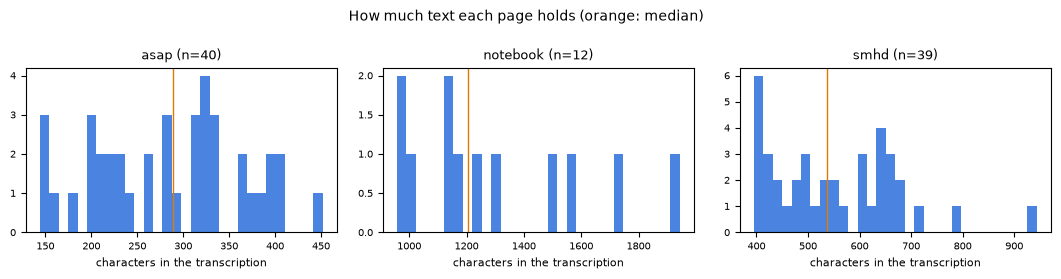

figure: eda_text_length.png


In [7]:
dev = pd.concat([dev, eda.image_sizes(dev["image"])], axis=1)
eda.show(dev.groupby("kind", sort=False)[["width", "height", "aspect"]].median(), "Median image size per kind:")
eda.histograms({k: part["chars"] for k, part in dev[dev["kind"].isin(["smhd", "asap", "notebook"])].groupby("kind")},
               "characters in the transcription", OUT / "eda_text_length.png",
               "How much text each page holds (orange: median)")

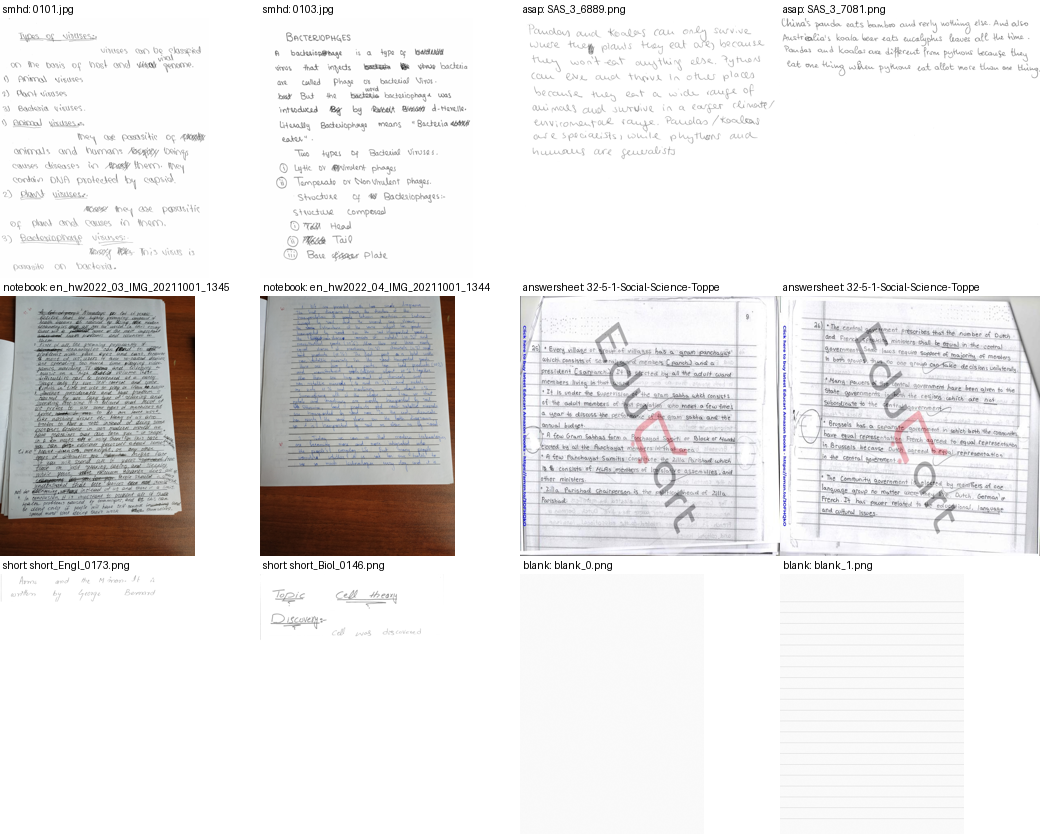

image: eda_pages.png


In [8]:
sample = dev.groupby("kind", sort=False).head(2)
eda.contact_sheet(sample["image"].tolist(), [f"{r.kind}: {Path(r.image).name}" for r in sample.itertuples()],
                  OUT / "eda_pages.png")

**What the EDA says.** The parts are very different, which is the point: SMHD pages are long scans of whole
pages, ASAP answers are short, wide strips of a few lines, notebooks are tall phone photos with shadows and
ruling, and the answer sheets are 640 x 640 crops. A reader that does well on all of them is not tuned to one
kind of page. Only the answer sheets look like Mendeley's numbered answers, and they have boxes but no text, so
there the reader can only be scored on how many numbers it finds.

## Part 4. Ink: how dark is each kind of page?

A page reader shown an empty page may write something anyway (step 2 saw it invent numbers on blank pages). The
cheapest safeguard is not to send an empty page at all. Ink is measured as the share of pixels at least 60 grey
levels darker than the page's own background (its median), so a light pen still counts while ruled lines and
scanner noise do not (`reader.ink`). Step 4 chooses the threshold from this table.


Ink (share of dark pixels) per kind of page:


,min,median,max
kind,,,
smhd,0.0181,0.0316,0.0717
asap,0.0076,0.0266,0.0565
notebook,0.1529,0.3313,0.3981
answersheet,0.0516,0.0912,0.1360
short,0.0020,0.0035,0.0099
blank,0.0000,0.0000,0.0000


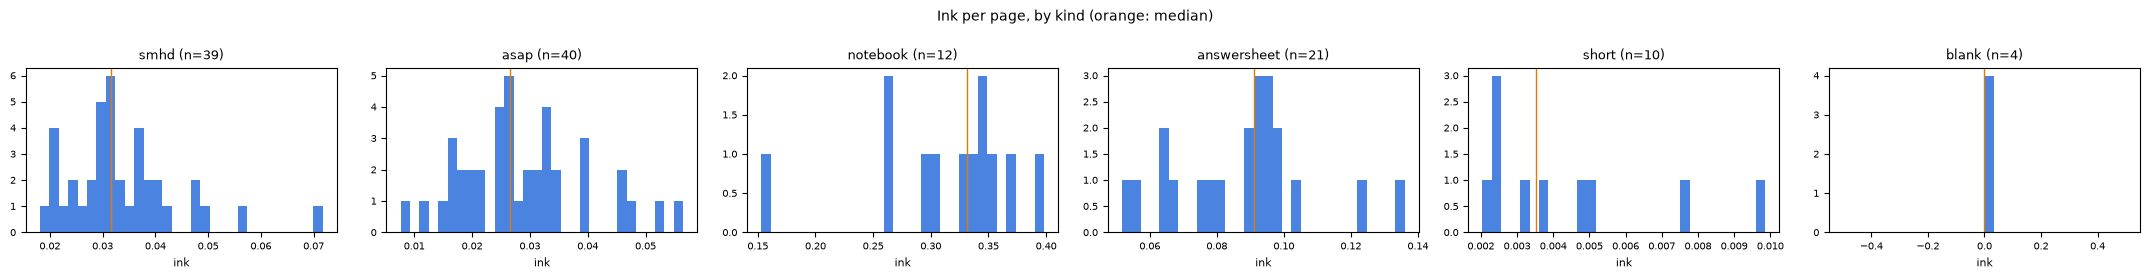

figure: eda_ink.png


In [9]:
dev["ink"] = [reader.ink(reader.load_pages(p)[0]) for p in dev["image"]]
ink = dev.groupby("kind", sort=False)["ink"].agg(["min", "median", "max"])
eda.show(ink, "Ink (share of dark pixels) per kind of page:", digits=4)
eda.histograms({k: part["ink"] for k, part in dev.groupby("kind", sort=False)}, "ink", OUT / "eda_ink.png",
               "Ink per page, by kind (orange: median)")
dev.drop(columns=["truth"]).assign(image=dev["image"].map(lambda p: Path(p).name)).to_csv(OUT / "devset.csv", index=False)

## Conclusion, and why it leads to step 4

The development set has 126 images of public handwriting: enough text to measure reading on three kinds of page,
every public numbered list we could find to measure question numbers, an answer-sheet booklet with boxed numbers,
and short and blank pages to catch a reader that invents. Blank pages have no ink at all (0.0000) and the lightest
written page, a short page of two lines, has 0.0020, so a blank-page threshold can sit between them. (Notebook
photos score far higher, 0.15 to 0.40, because their printed grid counts as ink; that does not matter here, as
the threshold only has to separate empty pages from written ones.) Step 4 now makes every choice of the reader
on this set.